# 🥭 MANGOST tutorial

This tutorial runs MANGOST end to end on a small **synthetic multi-section dataset** that ships with the repository
(`data/mangost_synthetic.h5ad`, 3 sections, about 4,100 spots, 300 genes, 5 laminar regions).

The synthetic tissue was built so that every region has

* its own **marker genes** (higher expression), and
* its own **gene co-expression programme**: a module of 15 genes that vary together *only inside that region*.

The second property is what MANGOST's routed gene networks are designed to find. Because we know the truth, we can check
both outputs of the model:

1. **spatial domains** from the spatial embedding `s'`, and
2. **region-specific gene networks** from the routing weights `alpha` and the networks `W_k`.

Runtime: about 5 minutes on a CPU, well under a minute on a GPU.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import anndata as ad
import mangost as mg

## 1. Data

MANGOST expects one `AnnData` with all sections stacked:

| field | content |
|---|---|
| `X` (or a layer) | raw counts, spots x genes |
| `obs["section"]` | section id of every spot |
| `obsm["spatial"]` | spot coordinates (any unit; the graph uses the spot pitch) |
| `obs["region"]` | *optional* annotation, used only for scoring and naming |

You can regenerate the example with `mg.datasets.make_synthetic()`.

In [2]:
adata = ad.read_h5ad("../data/mangost_synthetic.h5ad")
adata

AnnData object with n_obs × n_vars = 4104 × 300
    obs: 'section', 'region'
    uns: 'synthetic_truth'
    obsm: 'spatial'

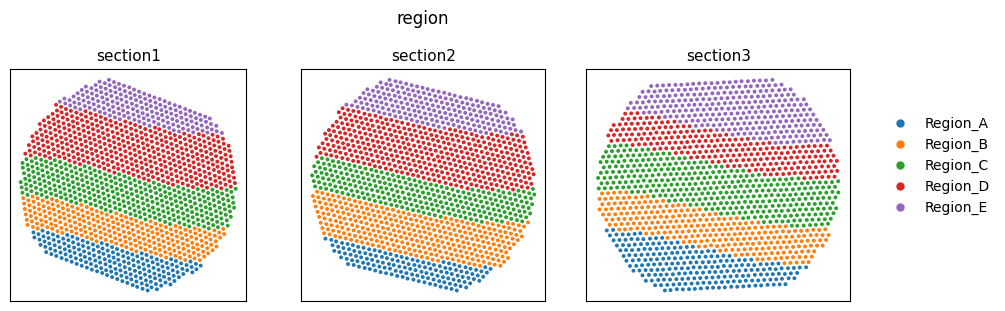

In [3]:
fig = mg.pl.spatial(adata, color="region")

## 2. Train

All sections are trained **jointly** with shared gene networks. The graph options follow the paper's single rule
(radius x spot pitch, optional expression pruning, optional input smoothing):

| dataset in the paper | `radius` | pruning | `hops` |
|---|---|---|---|
| DLPFC (Visium) | 1.5 | `cut=0.75` | 0 |
| Ortiz ST | 1.5 | `cut_quantile=0.4` | 0 |
| MERFISH | 3.0 | none | 6 |
| STARmap PLUS | 1.5 | none | 0 |

The synthetic data is a gene panel, so we keep all genes (`n_hvg=None`); for whole-transcriptome data the default
selects 4,000 highly variable genes.

In [4]:
model = mg.MANGOST(K=10, epochs=600, seed=0)
model.fit(adata, section_key="section", n_hvg=None, radius=1.5)

🥭 MANGOST: preparing sections


  section1: 1368 spots, 3971 edges (mean degree 5.81)


  section2: 1368 spots, 3971 edges (mean degree 5.81)


  section3: 1368 spots, 3971 edges (mean degree 5.81)
🥭 training: 3 sections, 300 genes, 300 network genes, K=10, device cpu


  epoch    0  spot 9.2305  net 1.0003  gate 0.0000  smooth 0.0027  use 0.0000


  epoch   50  spot 2.7528  net 0.9195  gate 0.0014  smooth 0.0009  use 0.0031


... (7 outputs left out)

  epoch  450  spot 2.6457  net 0.7305  gate 0.0180  smooth 0.0278  use 0.0004


  epoch  500  spot 2.6430  net 0.7278  gate 0.0183  smooth 0.0282  use 0.0002


  epoch  550  spot 2.6412  net 0.7253  gate 0.0181  smooth 0.0284  use 0.0000


  epoch  599  spot 2.6411  net 0.7245  gate 0.0180  smooth 0.0290  use 0.0000
🥭 done: networks in use [1, 2, 3, 4, 5, 6, 7, 9]


The fit adds two arrays to `adata`:

* `adata.obsm["X_mangost"]`: the 30-dim spatial embedding `s'`
* `adata.obsm["mangost_alpha"]`: the routing weights of every spot over the `K` networks

## 3. Spatial domains

Domains are obtained by clustering `s'` separately in each section. The paper uses R `mclust` (model `EEE`, seed 2020)
with `k` = number of annotated regions in the section; `method="gmm"` is a pure-Python fallback.

In [5]:
mg.tl.cluster_domains(adata, groupby="region", method="mclust")   # or method="gmm" without R
mg.tl.score(adata, "mangost_domain", "region")

,ARI,NMI
section,,
section1,0.963,0.952
section2,0.980,0.971
section3,0.972,0.962
mean,0.972,0.961


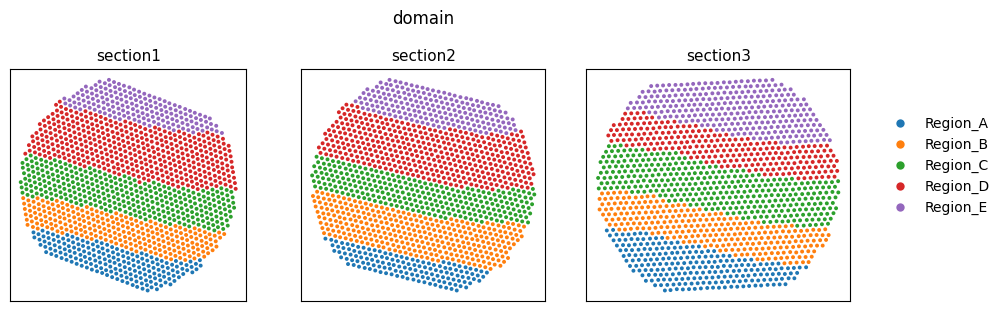

In [6]:
mg.tl.match_to_reference(adata, "mangost_domain", "region", out_key="domain")   # names/colours only
fig = mg.pl.spatial(adata, color="domain")

## 4. Where is each gene network used?

The routing weight `alpha_ik` says how much spot *i* uses network *k*. Averaging it within each region gives the
region usage of the networks (raw means; rows need not sum to one).

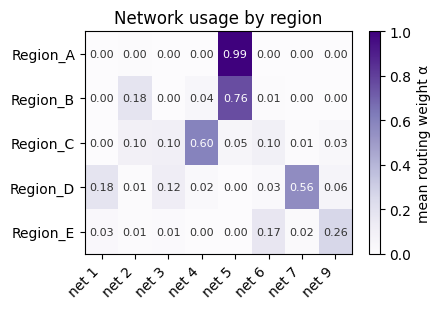

In [7]:
usage = mg.tl.region_usage(adata, groupby="region")
fig = mg.pl.usage_heatmap(usage)

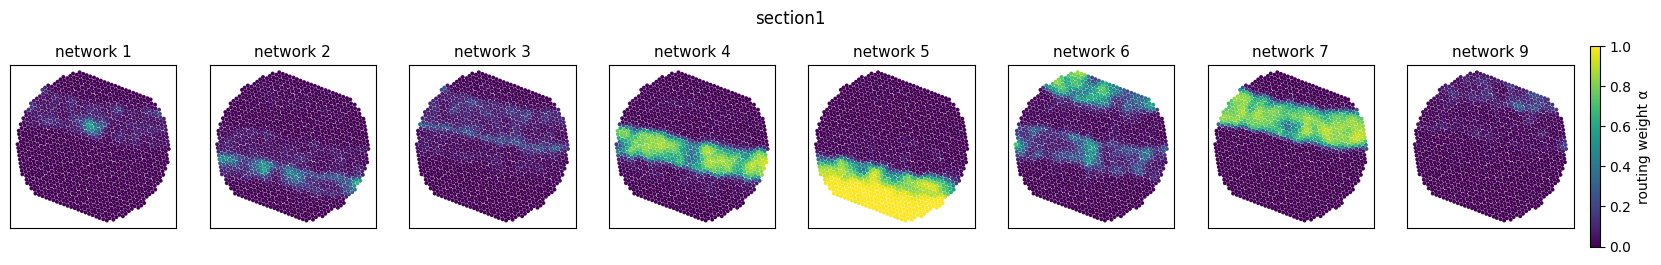

In [8]:
fig = mg.pl.routing(adata, section="section1")

In [9]:
sets = mg.tl.regional_sets(usage, threshold=0.5)   # regions with mean alpha >= 0.5 (else the highest-usage region)
sets

{'net 1': ['Region_D (fallback)'],
 'net 2': ['Region_B (fallback)'],
 'net 3': ['Region_D (fallback)'],
 'net 4': ['Region_C'],
 'net 5': ['Region_A', 'Region_B'],
 'net 6': ['Region_E (fallback)'],
 'net 7': ['Region_D'],
 'net 9': ['Region_E (fallback)']}

## 5. Which genes does a network link?

`model.network_deviation(k)` returns `Delta W_k = W_k - mean(W)`, the part of network *k* that is specific to it.
Its **hub genes** (largest total region-specific association) should be the genes of the planted module of the
region that uses the network. With 300 genes, a random set of 15 genes would contain fewer than one module gene.

In [10]:
used = adata.uns["mangost"]["used_networks"]
truth = adata.uns["synthetic_truth"]["modules"]
rows = []
for col, regs in sets.items():
    k = int(col.split()[1])
    hubs = list(model.hub_genes(k, n=15, networks=used).index)
    for r in regs:
        r = r.replace(" (fallback)", "")
        rows.append({"network": col, "region": r, "hub genes in the region's module": f"{len(set(hubs) & set(truth[r]))} / 15"})
import pandas as pd; pd.DataFrame(rows)

,network,region,hub genes in the region's module
0,net 1,Region_D,4 / 15
1,net 2,Region_B,4 / 15
2,net 3,Region_D,2 / 15
3,net 4,Region_C,1 / 15
4,net 5,Region_A,5 / 15
5,net 5,Region_B,6 / 15
6,net 6,Region_E,1 / 15
7,net 7,Region_D,4 / 15
8,net 9,Region_E,4 / 15


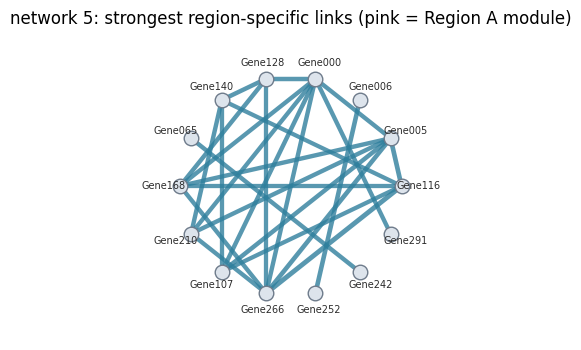

In [11]:
k = int(usage.loc["Region_A"].idxmax().split()[1])          # the network used by Region A
edges = model.top_edges(k, n=25, networks=used)
fig = mg.pl.network_graph(edges, highlight=truth["Region_A"], title=f"network {k}: strongest region-specific links (pink = Region A module)")

## 6. Save and reload

In [12]:
model.save("mangost_synthetic.pt")
adata.write_h5ad("mangost_synthetic_result.h5ad")
reloaded = mg.MANGOST.load("mangost_synthetic.pt")
reloaded.hub_genes(k, n=5, networks=used)

Gene159    2.910460
Gene242    2.866088
Gene160    2.839996
Gene063    2.826988
Gene021    2.798237
dtype: float32

## Next steps

* Run on your own data: `python scripts/run_mangost.py your_data.h5ad --label region --out results/`
* Pathway enrichment of a network: rank genes by `model.network_deviation(k).clip(lower=0).sum(1)` and use preranked GSEA
  (e.g. GSEApy).